In [63]:
# IMPORTS

# pip install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from ydata_profiling import ProfileReport


In [64]:
df = pd.read_csv('lego_sets.csv')
df.head()

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,star_rating,theme_name,val_star_rating,country
0,6-12,29.99,2.0,277.0,4.0,Catapult into action and take back the eggs fr...,75823.0,Use the staircase catapult to launch Red into ...,Average,Bird Island Egg Heist,4.5,Angry Birds™,4.0,US
1,6-12,19.99,2.0,168.0,4.0,Launch a flying attack and rescue the eggs fro...,75822.0,Pilot Pig has taken off from Bird Island with ...,Easy,Piggy Plane Attack,5.0,Angry Birds™,4.0,US
2,6-12,12.99,11.0,74.0,4.3,Chase the piggy with lightning-fast Chuck and ...,75821.0,Pitch speedy bird Chuck against the Piggy Car....,Easy,Piggy Car Escape,4.3,Angry Birds™,4.1,US
3,12+,99.99,23.0,1032.0,3.6,Explore the architecture of the United States ...,21030.0,Discover the architectural secrets of the icon...,Average,United States Capitol Building,4.6,Architecture,4.3,US
4,12+,79.99,14.0,744.0,3.2,Recreate the Solomon R. Guggenheim Museum® wit...,21035.0,Discover the architectural secrets of Frank Ll...,Challenging,Solomon R. Guggenheim Museum®,4.6,Architecture,4.1,US


### step 0:
creating new interesting columns and fixing current ones


In [65]:
df['country'].unique()

array(['US', 'AU', 'AT', 'BE', 'CA', 'CH', 'CZ', 'DE', 'DN', 'ES', 'FI',
       'FR', 'GB', 'IE', 'IT', 'LU', 'NO', 'NL', 'NZ', 'PL', 'PT'],
      dtype=object)

In [66]:
# This code makes the column 'continent' instead of country, which can be then turned into three separate columns.

country_to_continent = {
    'US': 'North America',
    'CA': 'North America',
    'AU': 'Oceania',
    'NZ': 'Oceania',
    'AT': 'Europe',
    'BE': 'Europe',
    'CH': 'Europe',
    'CZ': 'Europe',
    'DE': 'Europe',
    'DN': 'Europe',   
    'ES': 'Europe',
    'FI': 'Europe',
    'FR': 'Europe',
    'GB': 'Europe',
    'IE': 'Europe',
    'IT': 'Europe',
    'LU': 'Europe',
    'NO': 'Europe',
    'NL': 'Europe',
    'PL': 'Europe',
    'PT': 'Europe',
}

df['continent'] = df['country'].map(country_to_continent)
df = df.drop('country', axis=1)

In [67]:
# Creating a new column 'price_per_brick' for more fun comparisons
# Some legosets might be more expensive even with less bricks than other sets
# Only for analytic purposes, doesn't work in ML

df['price_per_brick'] = df['list_price'] / df['piece_count']
df['price_per_brick'] = df['price_per_brick'].round(4)
df['price_per_brick']


0        0.1083
1        0.1190
2        0.1755
3        0.0969
4        0.1075
          ...  
12256    0.1073
12257    0.1124
12258    0.1047
12259    0.2539
12260    0.1118
Name: price_per_brick, Length: 12261, dtype: float64

In [68]:
df['ages'].value_counts()
# Separate this column to two new columns - minAge and maxAge

ages
6-12     1476
7-14     1421
8-14     1180
4-7       957
5-12      911
10+       870
2-5       840
7-12      723
9-14      624
16+       420
8-12      350
4-99      311
12+       298
6-14      233
8+        226
1½-3      213
14+       212
10-21     184
6+        148
10-16     148
1½-5      113
9-16       92
5+         71
11-16      66
9-12       46
12-16      42
4+         21
9+         21
5-8        21
10-14      21
7+          2
Name: count, dtype: int64

In [69]:
# This code is 98% claude
# The primary function is to separate the 'ages' column into two different columns - min and max ages

import re

def parse_min_age(age_str):
    if pd.isna(age_str):
        return None

    age_str = str(age_str).strip()
    age_str = age_str.replace('½', '.5')  # handle fractions like 1½ -> 1.5

    # Grab the first number in the string. This covers "12+", "12-16", and "2".
    match = re.search(r'\d*\.?\d+', age_str)
    return float(match.group()) if match else None

df['min_age'] = df['ages'].apply(parse_min_age)

In [70]:
df['min_age'].isna().sum()

# Just a sanity check

np.int64(0)

In [71]:
# Mapping the review_difficulty column
review_mapper = {'Very Easy': 0, 'Easy': 1, 'Average': 2, 'Challenging': 3, 'Very Challenging': 4}
df['review_difficulty'] = df['review_difficulty'].map(review_mapper)

In [72]:
# Separate the 'continent' column to it's own columns

df = pd.get_dummies(df, columns=['continent'], dtype=int)
df.head()

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,star_rating,theme_name,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania
0,6-12,29.99,2.0,277.0,4.0,Catapult into action and take back the eggs fr...,75823.0,Use the staircase catapult to launch Red into ...,2.0,Bird Island Egg Heist,4.5,Angry Birds™,4.0,0.1083,6.0,0,1,0
1,6-12,19.99,2.0,168.0,4.0,Launch a flying attack and rescue the eggs fro...,75822.0,Pilot Pig has taken off from Bird Island with ...,1.0,Piggy Plane Attack,5.0,Angry Birds™,4.0,0.1190,6.0,0,1,0
2,6-12,12.99,11.0,74.0,4.3,Chase the piggy with lightning-fast Chuck and ...,75821.0,Pitch speedy bird Chuck against the Piggy Car....,1.0,Piggy Car Escape,4.3,Angry Birds™,4.1,0.1755,6.0,0,1,0
3,12+,99.99,23.0,1032.0,3.6,Explore the architecture of the United States ...,21030.0,Discover the architectural secrets of the icon...,2.0,United States Capitol Building,4.6,Architecture,4.3,0.0969,12.0,0,1,0
4,12+,79.99,14.0,744.0,3.2,Recreate the Solomon R. Guggenheim Museum® wit...,21035.0,Discover the architectural secrets of Frank Ll...,3.0,Solomon R. Guggenheim Museum®,4.6,Architecture,4.1,0.1075,12.0,0,1,0


In [73]:
df_original = df.copy()

In [74]:
# Making a separate dataset that includes themes
df_themes = pd.get_dummies(df, columns=['theme_name'], dtype=int)
df_themes = df_themes.dropna()
df_themes = df_themes.drop_duplicates()

In [75]:
df_themes

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,...,theme_name_Power Functions,theme_name_Pteranodon Chase,theme_name_SERIOUS PLAY®,theme_name_Speed Champions,theme_name_Star Wars™,theme_name_Stygimoloch Breakout,theme_name_T. rex Transport,theme_name_THE LEGO® BATMAN MOVIE,theme_name_THE LEGO® NINJAGO® MOVIE™,theme_name_Technic
0,6-12,29.9900,2.0,277.0,4.0,Catapult into action and take back the eggs fr...,75823.0,Use the staircase catapult to launch Red into ...,2.0,Bird Island Egg Heist,...,0,0,0,0,0,0,0,0,0,0
1,6-12,19.9900,2.0,168.0,4.0,Launch a flying attack and rescue the eggs fro...,75822.0,Pilot Pig has taken off from Bird Island with ...,1.0,Piggy Plane Attack,...,0,0,0,0,0,0,0,0,0,0
2,6-12,12.9900,11.0,74.0,4.3,Chase the piggy with lightning-fast Chuck and ...,75821.0,Pitch speedy bird Chuck against the Piggy Car....,1.0,Piggy Car Escape,...,0,0,0,0,0,0,0,0,0,0
3,12+,99.9900,23.0,1032.0,3.6,Explore the architecture of the United States ...,21030.0,Discover the architectural secrets of the icon...,2.0,United States Capitol Building,...,0,0,0,0,0,0,0,0,0,0
4,12+,79.9900,14.0,744.0,3.2,Recreate the Solomon R. Guggenheim Museum® wit...,21035.0,Discover the architectural secrets of Frank Ll...,3.0,Solomon R. Guggenheim Museum®,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12131,9-14,213.4878,6.0,1413.0,4.3,Jump to lightspeed in the Millennium Falcon!,75212.0,"Travel with Han Solo, Chewbacca and their frie...",2.0,Kessel Run Millennium Falcon™,...,0,0,0,0,1,0,0,0,0,0
12145,9-14,153.7078,15.0,825.0,4.7,Play at warp speed with Obi-Wan’s Jedi Starfig...,75191.0,Speed across the galaxy with Obi-Wan’s Jedi St...,2.0,Jedi Starfighter™ With Hyperdrive,...,0,0,0,0,1,0,0,0,0,0
12193,6-12,19.5078,6.0,102.0,4.2,Take on the Separatists with the Jedi and Clon...,75206.0,Command your own LEGO® Star Wars Jedi & Clone ...,0.0,Jedi™ and Clone Troopers™ Battle Pack,...,0,0,0,0,1,0,0,0,0,0
12194,6-12,19.5078,6.0,99.0,4.6,Patrol the Empire and enforce the rule of law!,75207.0,Play out Imperial law-enforcing scenarios with...,0.0,Imperial Patrol Battle Pack,...,0,0,0,0,1,0,0,0,0,0


In [76]:
# dropping unnessary columns, most of these columns are just set names or descriptions of the sets
droppables = ['prod_desc', 'prod_long_desc', 'set_name', 'ages', 'prod_id', 'theme_name']
df = df.drop(droppables, axis=1)


droppables_theme = ['prod_desc', 'prod_long_desc', 'set_name', 'ages', 'prod_id']
df_themes = df_themes.drop(droppables_theme, axis=1)

### step 1a:

In [77]:
df.dtypes

list_price                 float64
num_reviews                float64
piece_count                float64
play_star_rating           float64
review_difficulty          float64
star_rating                float64
val_star_rating            float64
price_per_brick            float64
min_age                    float64
continent_Europe             int64
continent_North America      int64
continent_Oceania            int64
dtype: object

### step 1b:

In [78]:
# # Making the ydata profile

# report = ProfileReport(df,
#     title='Lego sets / Advanced Data Analytics, 2026'
# )
# report.to_file("lego_sets_regression_report.html")

In [79]:
print(df.shape)

(12261, 12)


In [80]:
df.duplicated().sum()

np.int64(5334)

### Step 1c:

In [81]:
zeros = (df == 0).sum()
zeros

list_price                     0
num_reviews                    0
piece_count                    0
play_star_rating               0
review_difficulty           1139
star_rating                    0
val_star_rating                0
price_per_brick                0
min_age                        0
continent_Europe            2767
continent_North America    10629
continent_Oceania          11126
dtype: int64

In [82]:
df[df['price_per_brick'] == 0]

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania


In [83]:
df = df[df['price_per_brick'] != 0]

# Dropping this outlier set

In [84]:
df.isna().sum()

list_price                    0
num_reviews                1620
piece_count                   0
play_star_rating           1775
review_difficulty          2055
star_rating                1620
val_star_rating            1795
price_per_brick               0
min_age                       0
continent_Europe              0
continent_North America       0
continent_Oceania             0
dtype: int64

In [85]:
df.duplicated().sum()

np.int64(5334)

In [86]:
dupes = df[df.duplicated(keep=False)].sort_values(list(df.columns))
dupes

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania
1482,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
2057,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
4555,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
5679,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
6777,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
7184,975.9878,198.0,7541.0,4.0,3.0,4.8,4.4,0.1294,16.0,1,0,0
8880,975.9878,198.0,7541.0,4.0,3.0,4.8,4.4,0.1294,16.0,1,0,0
2462,1035.7800,198.0,7541.0,4.0,3.0,4.8,4.4,0.1374,16.0,1,0,0
9430,1035.7800,198.0,7541.0,4.0,3.0,4.8,4.4,0.1374,16.0,1,0,0


In [87]:
df[df.isna().any(axis=1)]

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania
22,9.9900,1.0,136.0,NaN,NaN,5.0,NaN,0.0735,10.0,0,1,0
32,19.9900,NaN,209.0,NaN,NaN,NaN,NaN,0.0956,10.0,0,1,0
48,49.9900,NaN,387.0,NaN,NaN,NaN,NaN,0.1292,5.0,0,1,0
55,99.9900,1.0,883.0,5.0,NaN,5.0,5.0,0.1132,7.0,0,1,0
69,39.9900,NaN,297.0,NaN,NaN,NaN,NaN,0.1346,5.0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
12136,36.5878,NaN,104.0,NaN,NaN,NaN,NaN,0.3518,8.0,1,0,0
12137,36.5878,NaN,101.0,NaN,NaN,NaN,NaN,0.3623,8.0,1,0,0
12196,243.9878,NaN,1967.0,NaN,NaN,NaN,NaN,0.1240,14.0,1,0,0
12214,24.3878,1.0,135.0,5.0,NaN,5.0,5.0,0.1807,7.0,1,0,0


In [88]:
df = df.dropna()
len(df)

10165

In [89]:
dupes = df[df.duplicated(keep=False)].sort_values(list(df.columns))
dupes

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania
1482,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
2057,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
4555,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
5679,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
6777,3.0378,180.0,1.0,4.0,0.0,4.8,4.6,3.0378,4.0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
7184,975.9878,198.0,7541.0,4.0,3.0,4.8,4.4,0.1294,16.0,1,0,0
8880,975.9878,198.0,7541.0,4.0,3.0,4.8,4.4,0.1294,16.0,1,0,0
2462,1035.7800,198.0,7541.0,4.0,3.0,4.8,4.4,0.1374,16.0,1,0,0
9430,1035.7800,198.0,7541.0,4.0,3.0,4.8,4.4,0.1374,16.0,1,0,0


In [90]:
df.duplicated().sum()

np.int64(4275)

In [91]:
df = df.drop_duplicates()
len(df)

5890

In [92]:
df.to_csv("lego_sets_cleaned.csv", index=False)

In [93]:
asdasdasd

NameError: name 'asdasdasd' is not defined

## Step 1d.

In [ ]:
df.columns

Index(['list_price', 'num_reviews', 'piece_count', 'play_star_rating',
       'review_difficulty', 'star_rating', 'val_star_rating',
       'price_per_brick', 'min_age', 'continent_Europe',
       'continent_North America', 'continent_Oceania'],
      dtype='object')

## Step 2a.

In [ ]:
# # Making a new ydata profile, after cleaning

# report = ProfileReport(df,
#     title='Lego sets / Advanced Data Analytics, 2026'
# )
# report.to_file("lego_sets_regression_report2.html")

In [ ]:
df['list_price'].kurtosis()

np.float64(27.21513694429366)

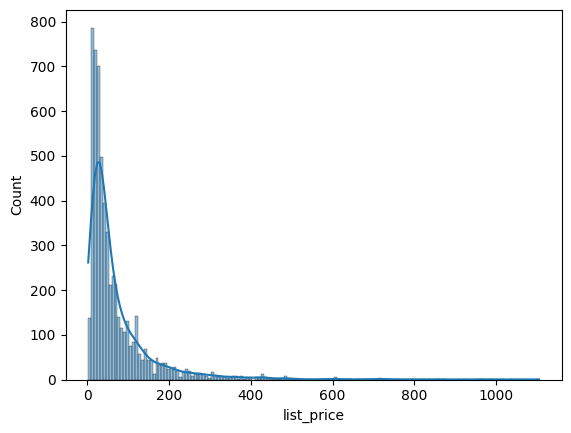

In [ ]:
sns.histplot(df['list_price'], kde=True)
plt.show()

## Step 2b.

<Axes: >

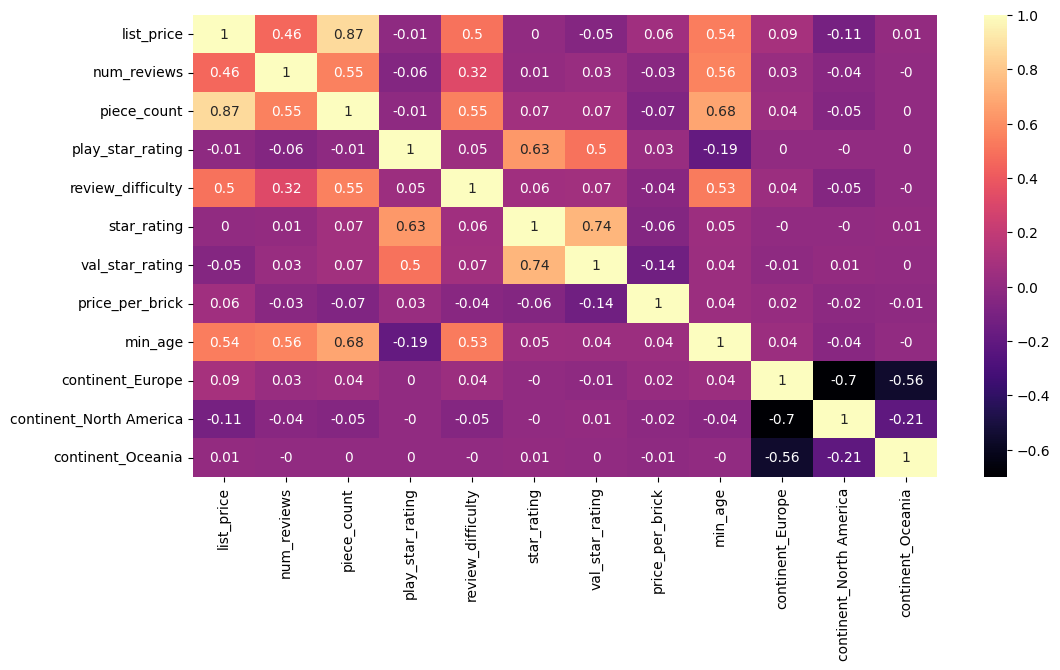

In [ ]:
corr = round(df.corr(),2)

plt.figure(figsize=(12,6))
sns.heatmap(corr, annot=True, cmap='magma')

interval columns not set, guessing: ['list_price', 'num_reviews', 'piece_count', 'play_star_rating', 'review_difficulty', 'star_rating', 'val_star_rating', 'price_per_brick', 'min_age', 'continent_Europe', 'continent_North America', 'continent_Oceania']


<Axes: >

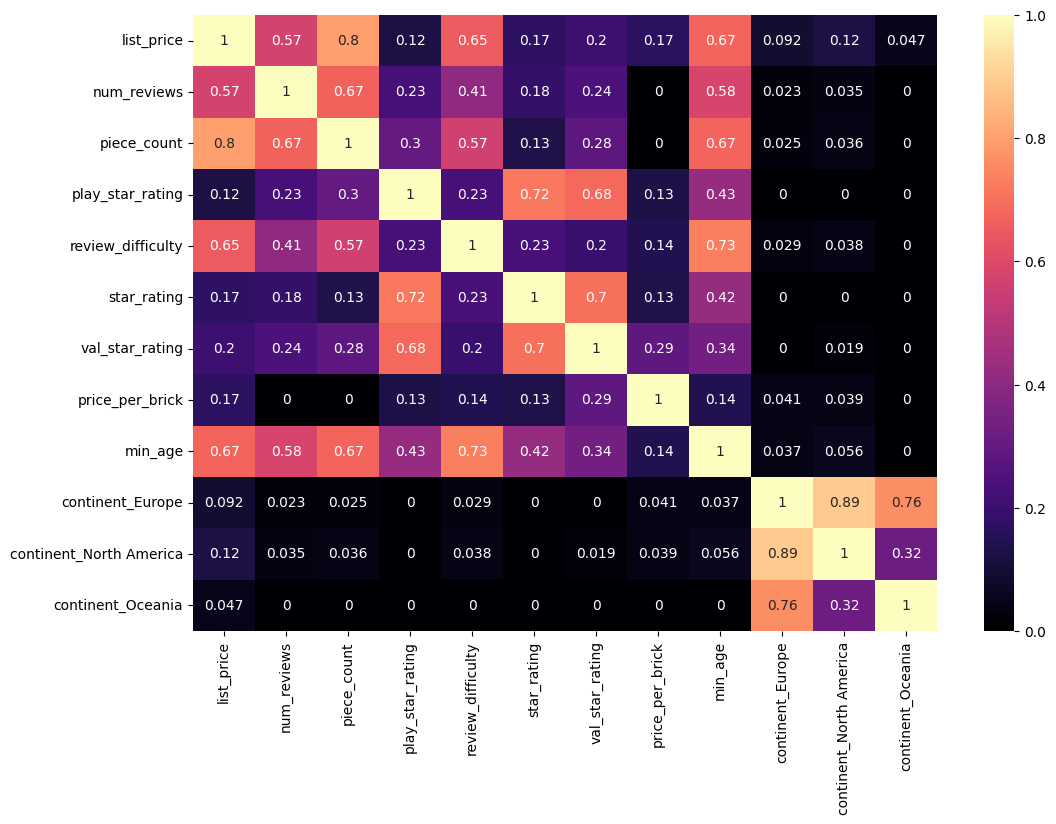

In [ ]:
import phik

phik_matrix = df.phik_matrix()

plt.figure(figsize=(12,8))

sns.heatmap(phik_matrix, annot=True, cmap='magma')

In [ ]:

pd.set_option('display.float_format', '{:.2f}'.format)

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical features (exclude target)
X = df.select_dtypes(include='number').drop(columns=['list_price'])

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values(by='VIF', ascending=False))

                    Feature                 VIF
8          continent_Europe 1000799917193443.50
10        continent_Oceania 1000799917193443.50
9   continent_North America 1000799917193443.50
4               star_rating                2.89
7                   min_age                2.55
5           val_star_rating                2.27
1               piece_count                2.27
2          play_star_rating                1.96
0               num_reviews                1.60
3         review_difficulty                1.59
6           price_per_brick                1.07


C:\Users\Niko Vuokila\AppData\Local\Temp\ipykernel_3484\703770320.py:12: UserWarning: The design matrix is poorly conditioned (condition number=5.99e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(X.values, i)
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\Data_Analytics&Deep_Learning\.venv_an\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\Data_Analytics&Deep_Learning\.venv_an\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\Data_Analytics&Deep_Learning\.venv_an\Lib\site-packages\statsmodels\stats\outliers_influence.py:23

## Step 2c.

In [ ]:
df.value_counts(df['list_price'])

list_price
19.99     87
9.99      83
19.49     83
10.13     79
29.99     79
          ..
573.99     1
579.74     1
588.89     1
590.58     1
605.74     1
Name: count, Length: 724, dtype: int64

In [ ]:
len(df)

5890

In [ ]:
# Checking the cardinality percentage of the dataset.

print("Unique value %:")
print()

for x in df.columns:
    count = round(df[x].nunique() / len(df) * 100, 2)
    print(f"{x}: {count}")

Unique value %:

list_price: 12.29
num_reviews: 1.46
piece_count: 7.08
play_star_rating: 0.51
review_difficulty: 0.08
star_rating: 0.46
val_star_rating: 0.56
price_per_brick: 39.39
min_age: 0.22
continent_Europe: 0.03
continent_North America: 0.03
continent_Oceania: 0.03


## Step 3a & b

In [ ]:
# I had to create a copy of the original df to see the hues from the themes.

top_5 = df_original['theme_name'].value_counts().head(10).index
df_top5 = df_original[df_original['theme_name'].isin(top_5)]

In [ ]:
df_original

,ages,list_price,num_reviews,piece_count,play_star_rating,prod_desc,prod_id,prod_long_desc,review_difficulty,set_name,star_rating,theme_name,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania
0,6-12,29.99,2.00,277.00,4.00,Catapult into action and take back the eggs fr...,75823.00,Use the staircase catapult to launch Red into ...,2.00,Bird Island Egg Heist,4.50,Angry Birds™,4.00,0.11,6.00,0,1,0
1,6-12,19.99,2.00,168.00,4.00,Launch a flying attack and rescue the eggs fro...,75822.00,Pilot Pig has taken off from Bird Island with ...,1.00,Piggy Plane Attack,5.00,Angry Birds™,4.00,0.12,6.00,0,1,0
2,6-12,12.99,11.00,74.00,4.30,Chase the piggy with lightning-fast Chuck and ...,75821.00,Pitch speedy bird Chuck against the Piggy Car....,1.00,Piggy Car Escape,4.30,Angry Birds™,4.10,0.18,6.00,0,1,0
3,12+,99.99,23.00,1032.00,3.60,Explore the architecture of the United States ...,21030.00,Discover the architectural secrets of the icon...,2.00,United States Capitol Building,4.60,Architecture,4.30,0.10,12.00,0,1,0
4,12+,79.99,14.00,744.00,3.20,Recreate the Solomon R. Guggenheim Museum® wit...,21035.00,Discover the architectural secrets of Frank Ll...,3.00,Solomon R. Guggenheim Museum®,4.60,Architecture,4.10,0.11,12.00,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12256,7-14,36.59,6.00,341.00,4.40,Protect NINJAGO® City from flying Manta Ray Bo...,70609.00,Help Cole save Shen-Li in this cool THE LEGO® ...,1.00,Manta Ray Bomber,4.30,THE LEGO® NINJAGO® MOVIE™,4.20,0.11,7.00,1,0,0
12257,7-14,24.39,8.00,217.00,4.10,Stop a Piranha Attack with Kai and Misako!,70629.00,Play out an action-packed Piranha Mech pursuit...,1.00,Piranha Attack,3.60,THE LEGO® NINJAGO® MOVIE™,4.10,0.11,7.00,1,0,0
12258,7-14,24.39,18.00,233.00,4.60,Stop a crime in the NINJAGO® City street market!,70607.00,"Team up with Lloyd Garmadon, Nya and Officer T...",1.00,NINJAGO® City Chase,4.60,THE LEGO® NINJAGO® MOVIE™,4.50,0.10,7.00,1,0,0
12259,6-14,12.19,1.00,48.00,5.00,Achieve Spinjitzu greatness with the Green Ninja!,70628.00,Learn all the skills of Spinjitzu with THE LEG...,0.00,Lloyd - Spinjitzu Master,5.00,THE LEGO® NINJAGO® MOVIE™,5.00,0.25,6.00,1,0,0


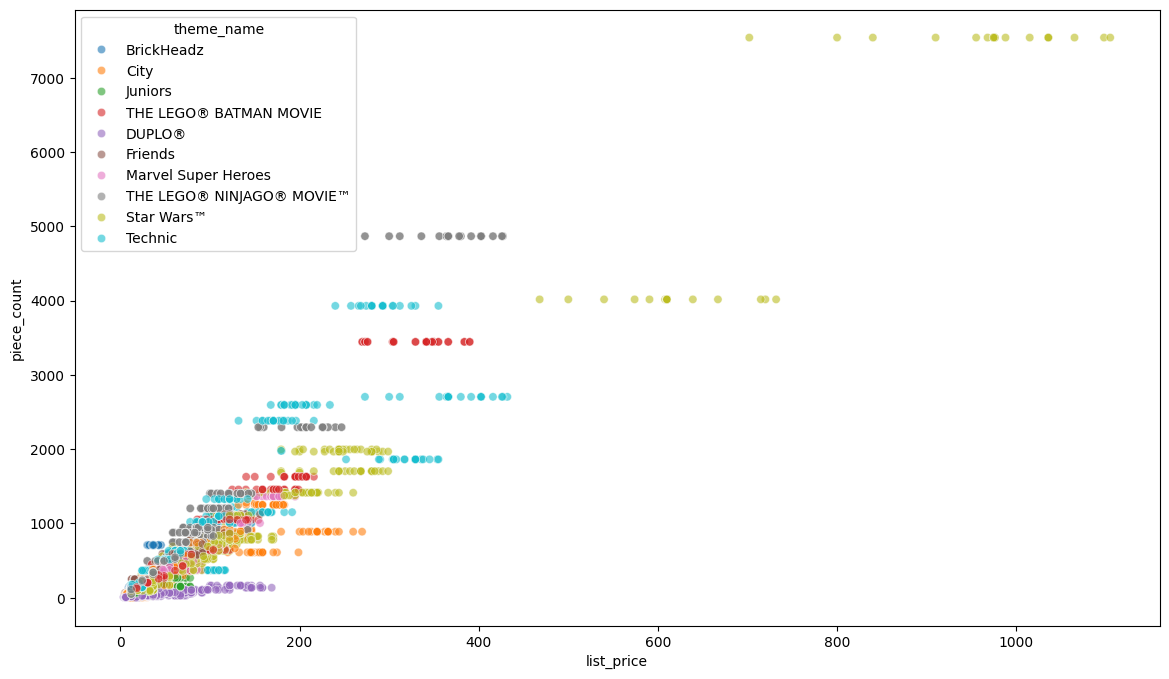

In [ ]:
plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=df_top5,
    x='list_price',
    y='piece_count',
    hue='theme_name',
    alpha=0.6
)

plt.show()

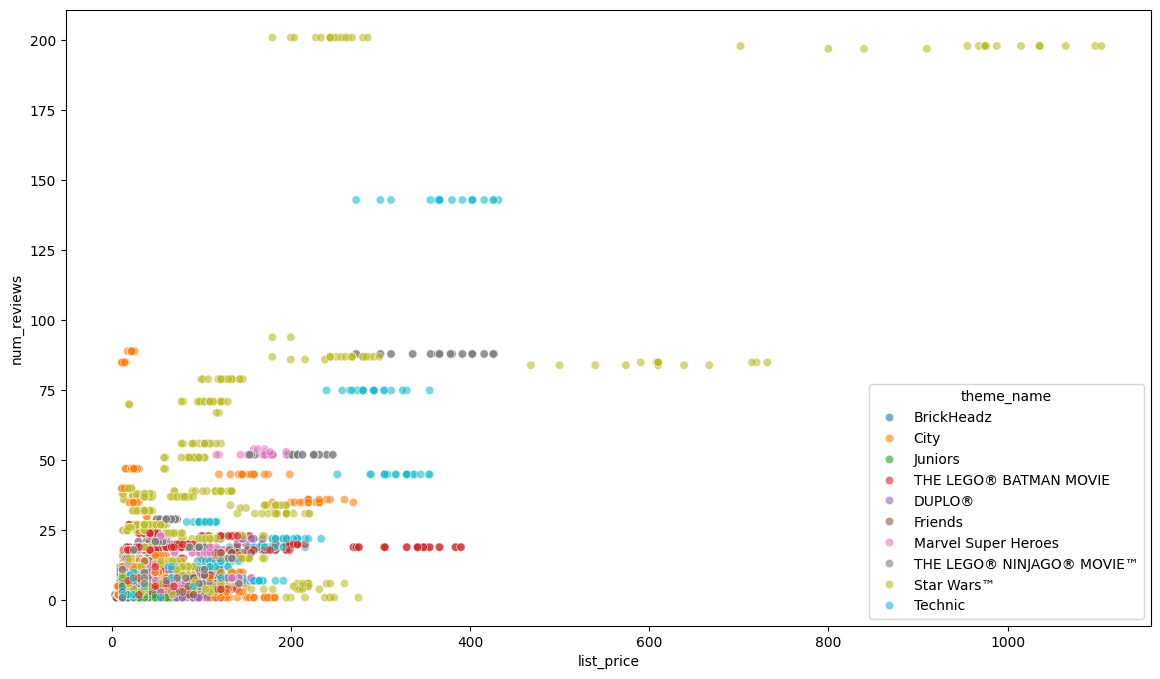

In [ ]:
plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=df_top5,
    x='list_price',
    y='num_reviews',
    hue='theme_name',
    alpha=0.6
)

plt.show()

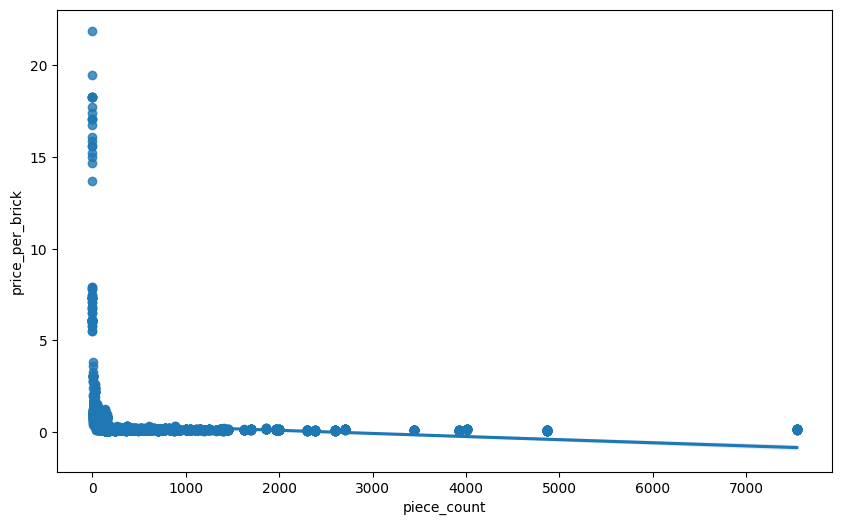

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_top5,
    x='piece_count',
    y='price_per_brick',
)

plt.show()

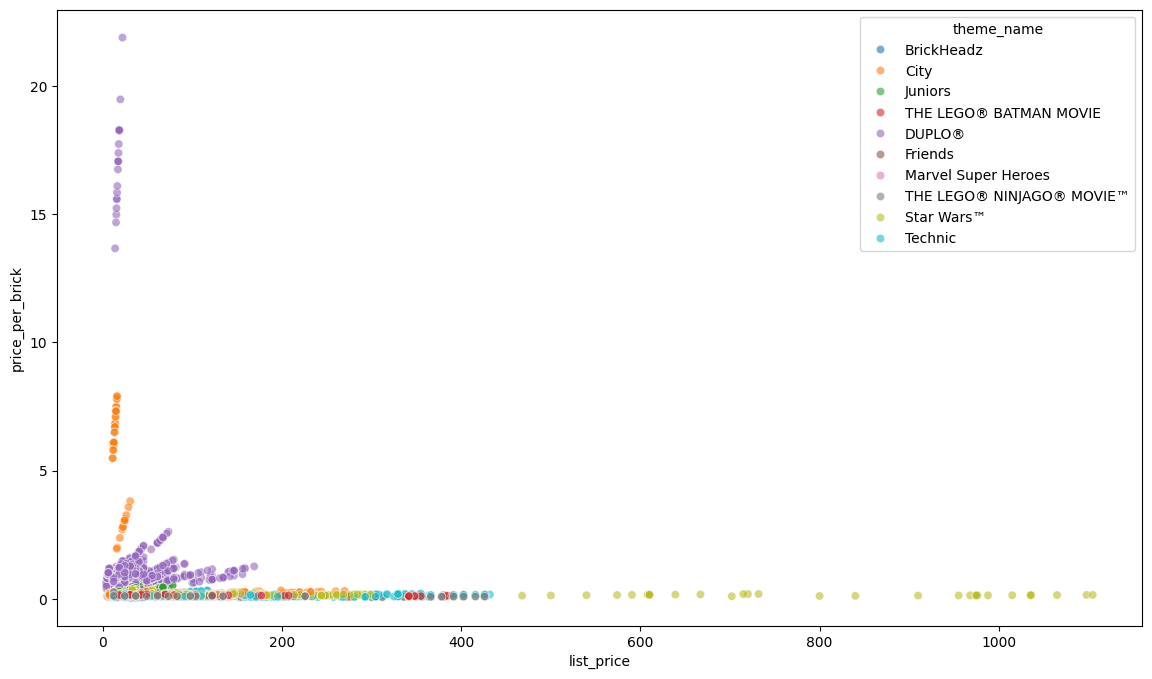

In [ ]:
plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=df_top5,
    x='list_price',
    y='price_per_brick',
    hue='theme_name',
    alpha=0.6
)

plt.show()

# This column is useless :(

In [ ]:
# sns.pairplot(df)

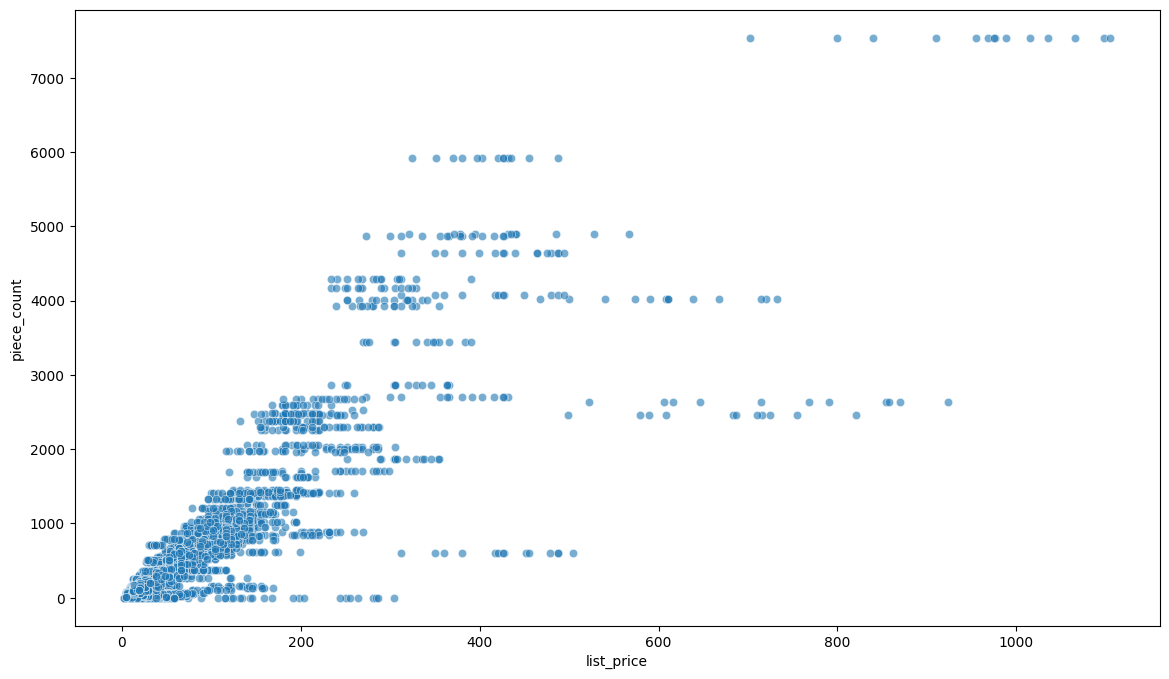

In [ ]:
plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=df,
    x='list_price',
    y='piece_count',
    alpha=0.6
)

plt.show()

## Step 3c.

In [ ]:
# can process the whole dataset 
# and compares variables to each other instead
# of focusing on outliers on a single variable
from sklearn.ensemble import IsolationForest

# adjust the contamination rate as you see fit
# for example, if you expect 5% of the data to be outliers
# you can use 0.05 etc. 

# basically, this is how aggressive Isolation Forest will be
# increase if you think you need to detect more outliers
# decrease if you need less outliers
iso = IsolationForest(contamination=0.005) 

# REMEMBER! Isolation Forest is a machine learning algorithm
# => ALL VARIABLES HAVE TO BE NUMERIC AT THIS POINT


# fit isolation forest
y_pred = iso.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

Inliers: 5861
Outliers: 29


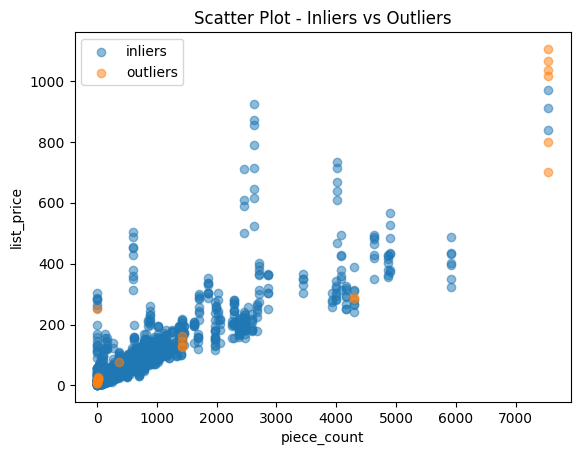

In [ ]:


# change the variable if you want to inspect this from other point of views
variable = "piece_count"
target = "list_price"

# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
inliers_sample = inliers.sample(3000)
outliers_sample = outliers.sample(25)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()

In [ ]:
outliers

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania
128,7.99,46.00,1.00,3.20,0.00,2.60,2.50,7.99,4.00,0,1,0
307,24.99,6.00,24.00,2.20,2.00,2.20,3.20,1.04,1.50,0,1,0
537,129.99,5.00,1426.00,2.00,3.00,2.60,1.80,0.09,9.00,0,1,0
694,799.99,197.00,7541.00,4.00,3.00,4.80,4.40,0.11,16.00,0,1,0
876,22.79,89.00,24.00,2.90,1.00,2.50,2.20,0.95,5.00,0,0,1
888,13.67,85.00,2.00,4.10,0.00,3.50,2.30,6.84,5.00,0,0,1
906,9.87,46.00,1.00,3.20,0.00,2.60,2.50,9.87,4.00,0,0,1
936,288.79,228.00,4295.00,4.20,3.00,4.80,4.60,0.07,16.00,0,0,1
1040,22.79,6.00,24.00,2.20,2.00,2.20,3.20,0.95,1.50,0,0,1
1171,250.79,1.00,1.00,5.00,2.00,4.00,3.00,250.79,10.00,0,0,1


In [ ]:
from sklearn.covariance import EllipticEnvelope

# contamination, same thing as in isolation
ee = EllipticEnvelope(contamination=0.005)

y_pred = ee.fit_predict(df)
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

# Add outlier
df["outlier"] = y_pred == -1

c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\Data_Analytics&Deep_Learning\.venv_an\Lib\site-packages\sklearn\covariance\_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-34.428720414814890 > -35.474400197760033). You may want to try with a higher value of support_fraction (current value: 0.501).
  warnings.warn(
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\Data_Analytics&Deep_Learning\.venv_an\Lib\site-packages\sklearn\covariance\_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-35.087268578057383 > -35.805316794238223). You may want to try with a higher value of support_fraction (current value: 0.501).
  warnings.warn(
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\Data_Analytics&Deep_Learning\.venv_an\Lib\site-packages\sklearn\covariance\_robust_covariance.py:188: RuntimeWarning: Determinant has increased; this should

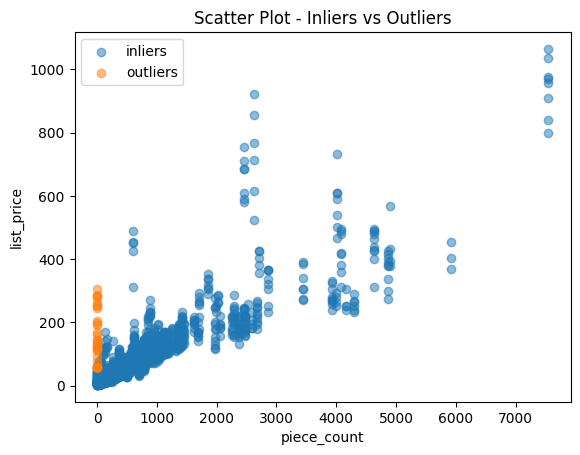

In [ ]:

# change the variable if you want to inspect this from other point of views
variable = "piece_count"
target = "list_price"

# if you want to reduce the number of points visualized
# sample a small amount of points, for example 300-500
inliers_sample = inliers.sample(3000)
outliers_sample = outliers.sample(30)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="outliers", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Outliers")
plt.legend()
plt.show()

In [ ]:
df_outliers = df[df['outlier'] == 1]
df_outliers

,list_price,num_reviews,piece_count,play_star_rating,review_difficulty,star_rating,val_star_rating,price_per_brick,min_age,continent_Europe,continent_North America,continent_Oceania,outlier
500,197.99,1.00,1.00,5.00,2.00,4.00,3.00,197.99,10.00,0,1,0,True
501,88.99,6.00,1.00,4.00,0.00,4.30,3.00,88.99,10.00,0,1,0,True
1171,250.79,1.00,1.00,5.00,2.00,4.00,3.00,250.79,10.00,0,0,1,True
1746,243.99,1.00,1.00,5.00,2.00,4.00,3.00,243.99,10.00,1,0,0,True
1747,121.99,6.00,1.00,4.00,0.00,4.30,3.00,121.99,10.00,1,0,0,True
2313,134.19,6.00,1.00,4.00,0.00,4.30,3.00,134.19,10.00,1,0,0,True
3027,167.69,1.00,1.00,5.00,2.00,4.00,3.00,167.69,10.00,0,1,0,True
3028,74.09,6.00,1.00,4.00,0.00,4.30,3.00,74.09,10.00,0,1,0,True
3701,254.90,1.00,1.00,5.00,2.00,4.00,3.00,254.90,10.00,1,0,0,True
3702,131.58,6.00,1.00,4.00,0.00,4.30,3.00,131.58,10.00,1,0,0,True


In [ ]:
df = df.drop(columns=['outlier'])

In [ ]:
df = df[(df['piece_count'] < 7000) & (df['piece_count'] > 1)]
df_themes = df_themes[(df_themes['piece_count'] < 7000) & (df_themes['piece_count'] > 1)]


## Step 3d

<Axes: >

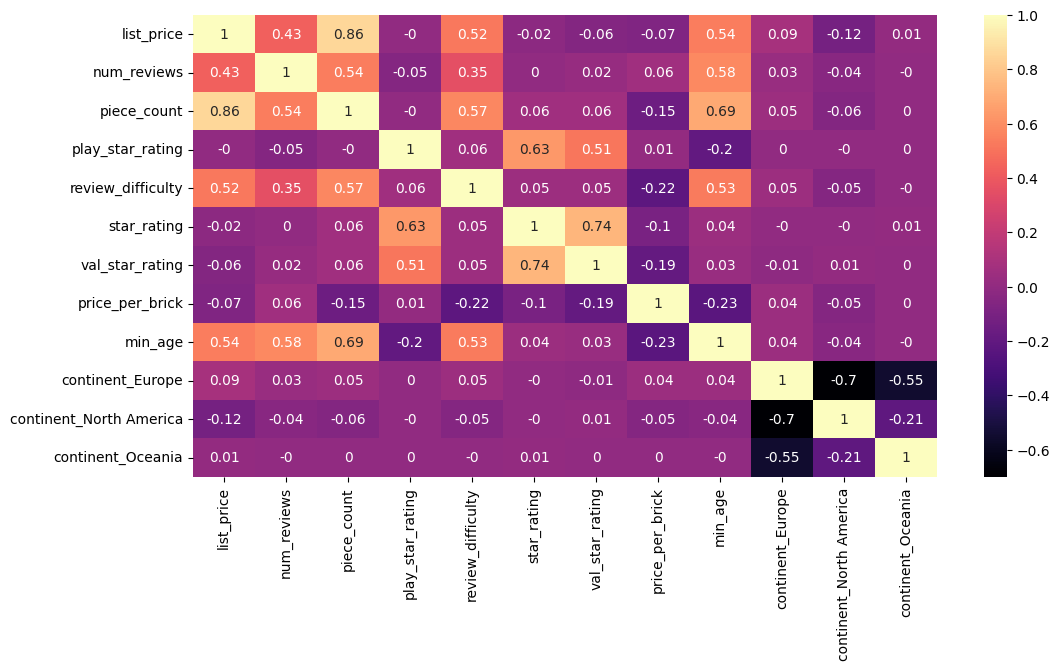

In [ ]:
corr = round(df.corr(),2)

plt.figure(figsize=(12,6))
sns.heatmap(corr, annot=True, cmap='magma')

interval columns not set, guessing: ['list_price', 'num_reviews', 'piece_count', 'play_star_rating', 'review_difficulty', 'star_rating', 'val_star_rating', 'price_per_brick', 'min_age', 'continent_Europe', 'continent_North America', 'continent_Oceania']


<Axes: >

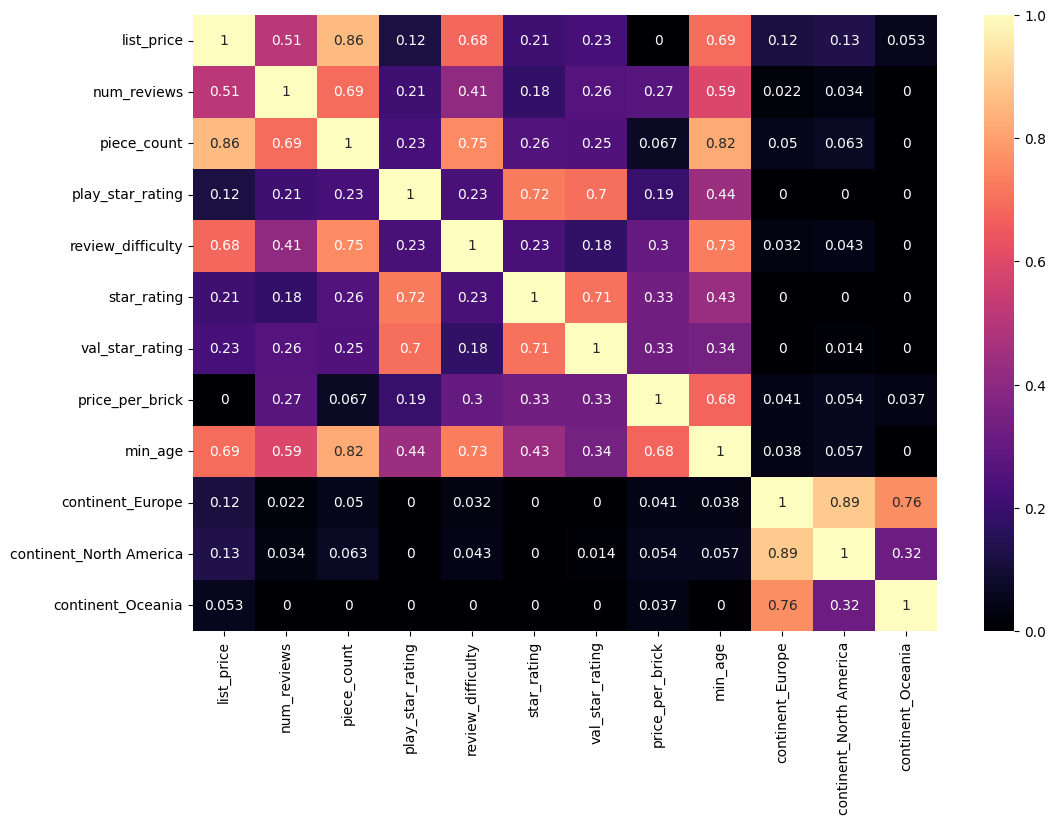

In [ ]:
phik_matrix = df.phik_matrix()

plt.figure(figsize=(12,8))

sns.heatmap(phik_matrix, annot=True, cmap='magma')

### Behold: A collection of plots made of some important looking connections

<Axes: xlabel='min_age', ylabel='piece_count'>

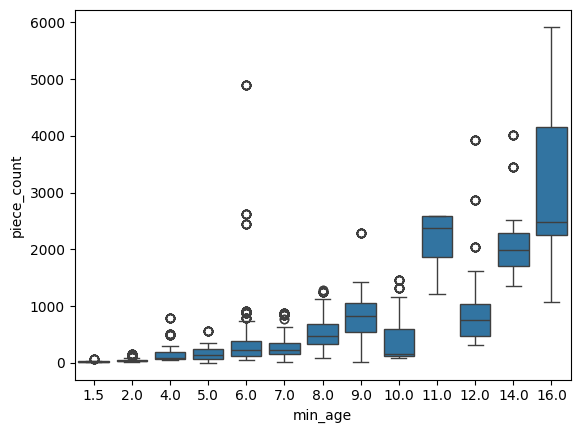

In [ ]:
sns.boxplot(df, x='min_age', y='piece_count')

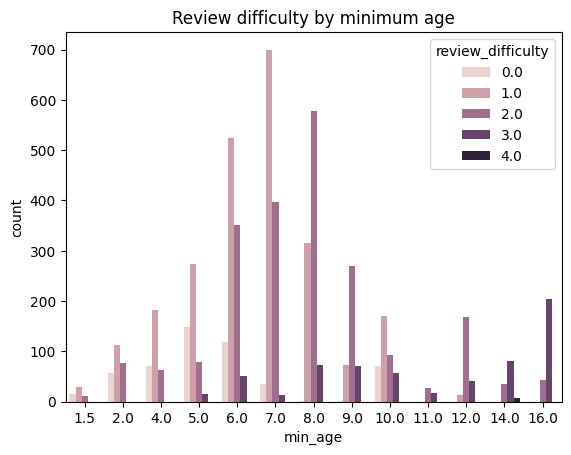

In [ ]:
sns.countplot(data=df, x='min_age', hue='review_difficulty')
plt.title('Review difficulty by minimum age')
plt.show()

<Axes: xlabel='min_age', ylabel='num_reviews'>

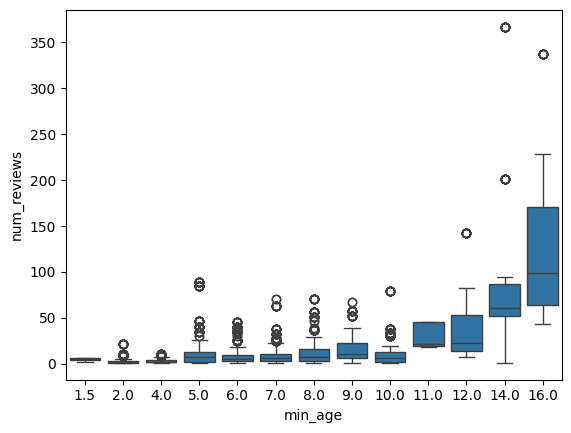

In [ ]:
sns.boxplot(df, x='min_age', y='num_reviews')

## Step 3e.

In [ ]:
# First I will try selectkbest

# x- and y-splits.
X = df_themes.drop(columns=['list_price', 'price_per_brick'])
y = df_themes['list_price']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

selector = SelectKBest(score_func=f_regression, k=10)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

selected_features = X_train.columns[selector.get_support()]

print(selected_features)

Index(['num_reviews', 'piece_count', 'review_difficulty', 'min_age',
       'continent_North America', 'theme_name_BrickHeadz',
       'theme_name_Creator Expert', 'theme_name_Ghostbusters™',
       'theme_name_MINDSTORMS®', 'theme_name_Technic'],
      dtype='object')


In [ ]:
results = pd.DataFrame({
    'Feature': X_train.columns,
    'Score': selector.scores_,
    'P-value': selector.pvalues_,
    'Selected': selector.get_support()
})

results = results.sort_values(by='Score', ascending=False)

print(results)

                                             Feature    Score  P-value  \
1                                        piece_count 17351.37     0.00   
6                                            min_age  2967.18     0.00   
3                                  review_difficulty  2604.40     0.00   
0                                        num_reviews  1507.35     0.00   
19                         theme_name_Creator Expert   593.57     0.00   
34                            theme_name_MINDSTORMS®   250.57     0.00   
28                          theme_name_Ghostbusters™   234.06     0.00   
14                             theme_name_BrickHeadz    93.76     0.00   
8                            continent_North America    73.72     0.00   
49                                theme_name_Technic    71.88     0.00   
7                                   continent_Europe    59.36     0.00   
31                                theme_name_Juniors    48.33     0.00   
18                         theme_name_

In [ ]:
#  Trying out RFE

from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

selector = RFE(
    estimator=model,
    n_features_to_select=10
)

X_train_rfe = selector.fit_transform(X_train, y_train)
X_test_rfe = selector.transform(X_test)

selected_features_rfe = X_train.columns[selector.get_support()]

print(selected_features_rfe)

Index(['num_reviews', 'piece_count', 'play_star_rating', 'star_rating',
       'val_star_rating', 'min_age', 'continent_Europe',
       'continent_North America', 'theme_name_MINDSTORMS®',
       'theme_name_Star Wars™'],
      dtype='object')


In [ ]:
df.groupby('continent_Oceania')['list_price'].mean()

continent_Oceania
0   70.88
1   73.02
Name: list_price, dtype: float64

In [ ]:
df.columns

Index(['list_price', 'num_reviews', 'piece_count', 'play_star_rating',
       'review_difficulty', 'star_rating', 'val_star_rating',
       'price_per_brick', 'min_age', 'continent_Europe',
       'continent_North America', 'continent_Oceania'],
      dtype='object')